# YOLO Training Visualization Demo


This notebook is designed specifically for classroom teaching.

The goal is **not to obtain the best detection accuracy**, but to help students
understand what happens during the YOLO training process.

Because a complete YOLO training process can take a long time, this notebook
uses a short training demonstration (5 epochs) so students can observe:

1. How a dataset is connected to YOLO training
2. The role of `data.yaml`
3. How a pretrained YOLO model is fine-tuned
4. What happens during each epoch
5. How training loss changes
6. Where trained model weights are saved

---

## Expected Learning Outcomes

After running this notebook, students should understand:

- The relationship between images, labels, and `data.yaml`
- The meaning of an epoch
- The purpose of loss functions
- How YOLO saves training results
- How a trained model can be used for detection

This notebook is a teaching demonstration. For real applications,
longer training, larger datasets, and hyperparameter tuning are usually required.


# 1. Install YOLO Environment

Google Colab normally provides PyTorch already, so there is no need to force-install a specific CUDA build. Installing `ultralytics` is sufficient for this notebook.


In [1]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 22.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 4.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.8/96.8 kB 3.1 MB/s eta 0:00:00


# 2. Download the Project Dataset from GitHub

For reproducibility, we directly use the dataset from the GitHub repository.

Students do not need to manually download images.

The repository contains:

- training images;
- validation images;
- YOLO label files;
- dataset configuration (`data.yaml`).


In [2]:
from pathlib import Path

REPO_URL = "https://github.com/yantaolab/Autonomous-Construction-and-Robotics.git"
REPO_PATH = Path("/content/Autonomous-Construction-and-Robotics")

if not REPO_PATH.exists():
    !git clone "{REPO_URL}"

PROJECT_PATH = REPO_PATH / "Projects/Project 03 Construction Tool Classification"

print("Project folder:")
print(PROJECT_PATH)


Cloning into 'Autonomous-Construction-and-Robotics'...
remote: Enumerating objects: 10889, done.
remote: Counting objects: 100% (263/263), done.
remote: Compressing objects: 100% (226/226), done.
remote: Total 10889 (delta 149), reused 39 (delta 33), pack-reused 10626 (from 3)
Receiving objects: 100% (10889/10889), 265.42 MiB | 17.46 MiB/s, done.
Resolving deltas: 100% (234/234), done.
Updating files: 100% (11052/11052), done.
Project folder:
/content/Autonomous-Construction-and-Robotics/Projects/Project 03 Construction Tool Classification


# 3. Understanding YOLO Dataset Configuration: data.yaml

Before training, YOLO needs to know where the data is located.

The file `data.yaml` provides this information.

Important fields:

- `train`: path to training images
- `val`: path to validation images
- `nc`: number of object classes
- `names`: class names

Example:

```yaml
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5
names: ['Drill', 'Hammer', 'Pliers', 'Screwdriver', 'Wrench']
```

YOLO reads this file automatically during training.


In [3]:
DATA_YAML = PROJECT_PATH / "data.yaml"

print(DATA_YAML.read_text())


train: ../train/images
val: ../valid/images
test: ../test/images

nc: 5
names: ['Drill', 'Hammer', 'Pliers', 'Screwdriver', 'Wrench']

roboflow:
  workspace: drone-fcvjd
  project: tools-bynck
  version: 7
  license: CC BY 4.0
  url: https://universe.roboflow.com/drone-fcvjd/tools-bynck/dataset/7


# 4. Load a Pretrained YOLO Model

We use a pretrained YOLO model instead of training from zero.

This approach is called **transfer learning**.

The model already learned general visual features.
Training adapts these features to our construction tool dataset.

For classroom demonstration, we use YOLOv8n because it trains relatively fast.


In [4]:
from ultralytics import YOLO

model = YOLO("yolov8n.pt")

print("Pretrained YOLO model loaded.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Pretrained YOLO model loaded.


# 5. Start YOLO Training Demonstration (5 Epochs)

## What is an epoch?

One epoch means that the model has seen the complete training dataset once.

Example:

- Epoch 1: first learning stage
- Epoch 2: model updates its parameters again
- ...
- Epoch 5: final demonstration stage

Only 5 epochs are used here because this notebook is for visualization and teaching.


In [5]:
from pathlib import Path

OUTPUT_DIR = Path("/content/yolo_training_demo")

results = model.train(
    data=str(DATA_YAML),
    epochs=5,
    imgsz=640,
    project=str(OUTPUT_DIR),
    name="student_training_demo"
)

print("Training completed.")


Ultralytics 8.4.176 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Autonomous-Construction-and-Robotics/Projects/Project 03 Construction Tool Classification/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, mul

# 6. Visualize Training Loss

During training YOLO records loss values.

Loss represents the difference between predictions and ground truth.


Generally, a decreasing loss indicates that the model is learning.

The purpose of this plot is to let students observe the training process.


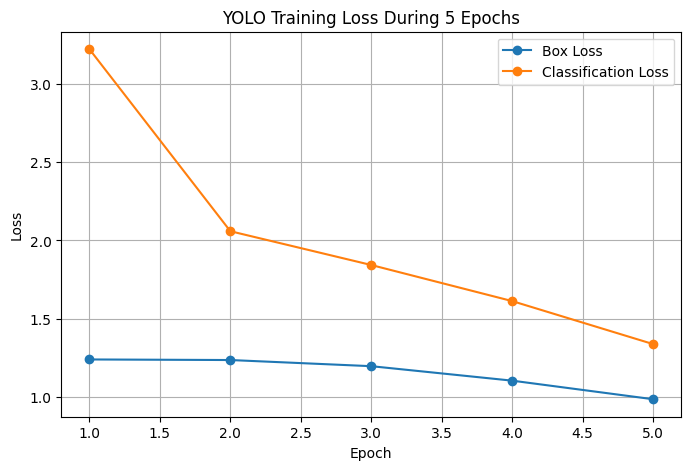

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

results_file = OUTPUT_DIR / "student_training_demo" / "results.csv"

history = pd.read_csv(results_file)

plt.figure(figsize=(8,5))

plt.plot(history["epoch"], history["train/box_loss"], marker="o", label="Box Loss")
plt.plot(history["epoch"], history["train/cls_loss"], marker="o", label="Classification Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("YOLO Training Loss During 5 Epochs")
plt.legend()
plt.grid(True)

plt.show()


# 7. Understand Training Output Files

After training YOLO creates a folder containing:

- `weights/best.pt`: best saved model weights
- `results.csv`: numerical training history
- plots and evaluation information

These files allow us to continue using or analyzing the trained model.


# 8. Load the Trained Model for Demonstration

The trained weights can be loaded again for inference.

This demonstrates the complete pipeline:

Training → Saved Weights → Detection


In [7]:
BEST_MODEL = OUTPUT_DIR / "student_training_demo" / "weights" / "best.pt"

trained_model = YOLO(str(BEST_MODEL))

print("Trained model loaded.")

from IPython.display import Image, display

CONF_THRESHOLD = 0.25

test_images = list((PROJECT_PATH / "test/images").glob("*"))

if len(test_images) > 0:
    test_image = test_images[0]

    prediction = trained_model.predict(
        source=str(test_image),
        conf=CONF_THRESHOLD
    )

    result_image = prediction[0].plot()

    display(Image(data=result_image))
else:
    print("Please select a test image manually.")



Trained model loaded.

image 1/1 /content/Autonomous-Construction-and-Robotics/Projects/Project 03 Construction Tool Classification/test/images/Screwdriver-900-_JPEG.rf.901cf249bbd4b4c3cc7889d7e15deacd.jpg: 640x640 1 Wrench, 371.5ms
Speed: 9.6ms preprocess, 371.5ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)


# Summary

This notebook demonstrated the complete YOLO training workflow:

Dataset
→
data.yaml
→
Pretrained YOLO Model
→
5 Epoch Training
→
Loss Visualization
→
Saved Weights
→
Object Detection

The purpose is to help students understand the training process before moving
to larger experiments and real-world model optimization.
